### **EN3150 – CNN Classification**
##### **01. Fashion-MNIST Data Exploration and Preprocessing**
This notebook performs the initial exploration and preprocessing of the Fashion-MNIST dataset for the EN3150 Assignment 03.
The main objectives are:
- Load the Fashion-MNIST dataset
- Understand the dataset structure
- Explore the image classes
- Visualize sample images
- Analyze class distribution
- Create training, validation, and testing sets
- Normalize the image data
- Prepare the images for CNN-based classification
- Verify the final dataset structure

#### **1. Dataset and Assignment Requirements**

The assignment requires a low-resolution image classification dataset and specifies a maximum image resolution of 64 × 64 pixels.
The dataset must be divided into:
- 70% Training
- 15% Validation
- 15% Testing

Fashion-MNIST is selected for this project because it consists of low-resolution grayscale images of clothing items. Each image has a resolution of 28 × 28 pixels, which satisfies the assignment's maximum resolution requirement. The dataset contains 10 different clothing categories.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter as ct
from sklearn.model_selection import train_test_split as tts
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


#### **2. Load the Fashion-MNIST Dataset**
Fashion-MNIST contains grayscale images of clothing items belonging to 10 classes.
Each image has a spatial resolution of 28 × 28 pixels.

In [3]:
# Load Fashion-MNIST
fashion_mnist = keras.datasets.fashion_mnist

(x_train_original, y_train_original), (x_test_original, y_test_original) = (fashion_mnist.load_data())

print("Original training images:", x_train_original.shape)
print("Original training labels:", y_train_original.shape)

print("Original test images:", x_test_original.shape)
print("Original test labels:", y_test_original.shape)

Original training images: (60000, 28, 28)
Original training labels: (60000,)
Original test images: (10000, 28, 28)
Original test labels: (10000,)


##### **Dataset Structure**
The original Fashion-MNIST dataset consists of:
- 60,000 training images
- 10,000 testing images
- Image resolution: 28 × 28 pixels
- Grayscale images
- 10 classification categories
Each image is represented as a 28 × 28 matrix of pixel intensity values.

In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

for index, name in enumerate(class_names):
    print(f"{index}: {name}")

0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot


#### **3. Explore the Dataset**
The labels are represented by integers from 0 to 9.
The corresponding clothing categories are:
| Label | Class |
|---:|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

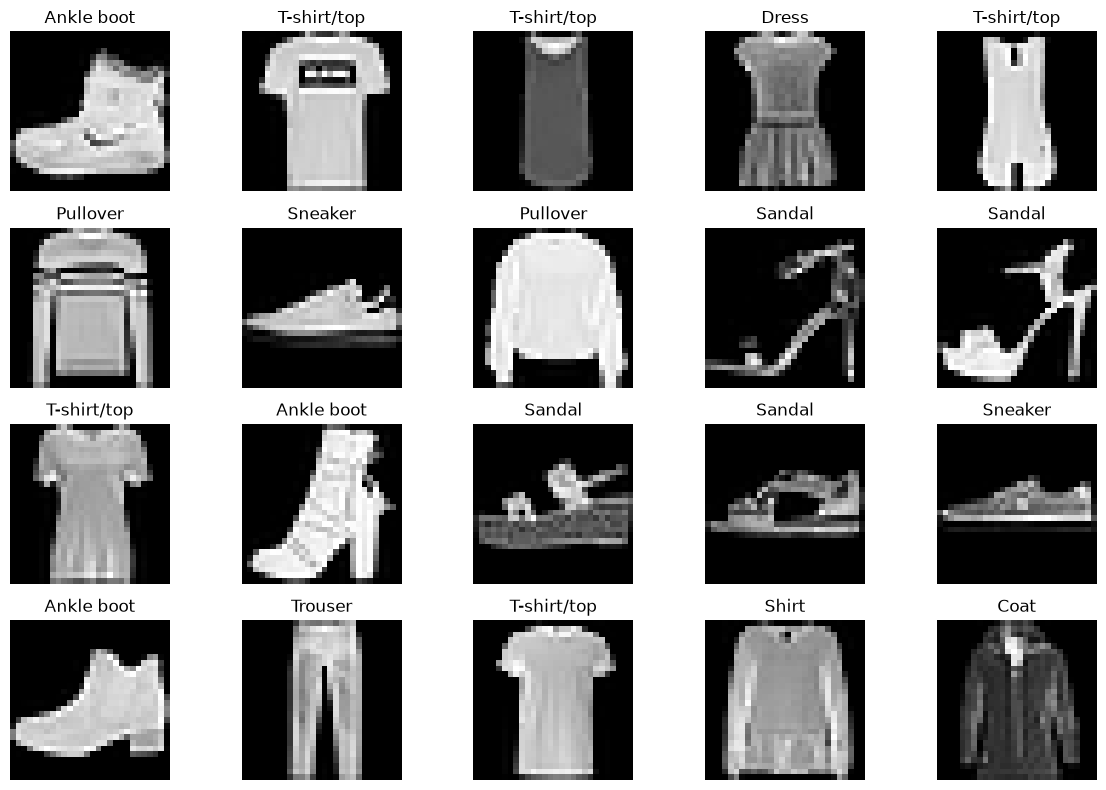

In [5]:
plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train_original[i], cmap="gray")
    plt.title(class_names[y_train_original[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

##### **Observations**
The images are grayscale and have a resolution of 28 × 28 pixels.
Although the images have relatively low spatial resolution, the different clothing categories contain visual patterns that can be learned using convolutional neural networks.
Some classes, such as T-shirt/top, Shirt, Pullover and Coat, may have visually similar structures. These similarities are expected to make some classification cases more challenging.

In [6]:
print("Data type:", x_train_original.dtype)
print("Minimum pixel value:", x_train_original.min())
print("Maximum pixel value:", x_train_original.max())

Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


#### **4. Pixel Value Analysis**
The original images use 8-bit grayscale pixel values.
The pixel intensity range is:
$$
0 \leq x \leq 255
$$

where:
- 0 represents black
- 255 represents the maximum intensity
Before training the CNN models, these values will be normalized to the range [0, 1].

In [7]:
train_class_counts = ct(y_train_original)

distribution_df = pd.DataFrame({
    "Class ID": list(range(10)),
    "Class Name": class_names,
    "Number of Images": [
        train_class_counts[i] for i in range(10)
    ]
})

distribution_df

,Class ID,Class Name,Number of Images
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


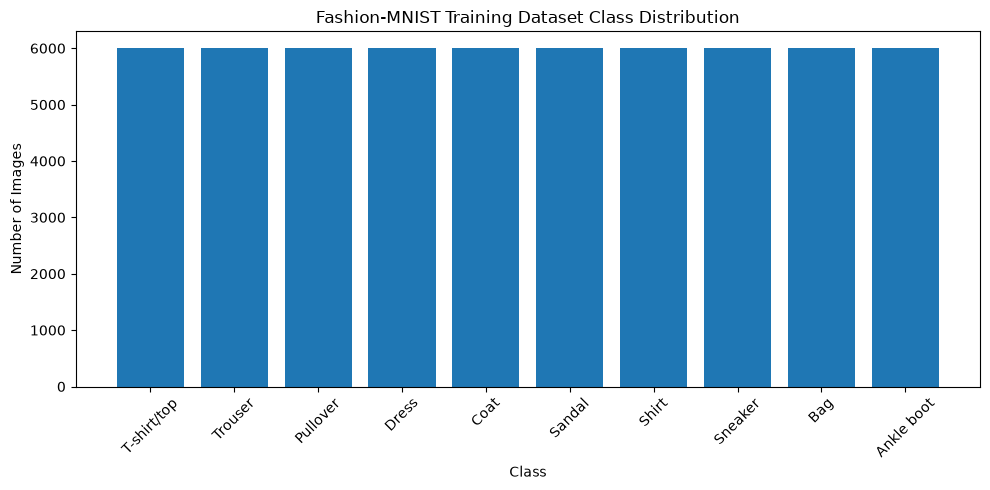

In [8]:
plt.figure(figsize=(10, 5))
plt.bar(class_names,distribution_df["Number of Images"])

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Fashion-MNIST Training Dataset Class Distribution")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### **Class Distribution Observation**
The class distribution is approximately balanced, with a similar number of samples available for each clothing category.
This is useful for classification because no individual class dominates the dataset.

In [9]:
# Combine the original training and testing datasets
X = np.concatenate([x_train_original, x_test_original],axis=0)
y = np.concatenate([y_train_original, y_test_original],axis=0)
print("Combined images:", X.shape)
print("Combined labels:", y.shape)

Combined images: (70000, 28, 28)
Combined labels: (70000,)


#### **5. Train / Validation / Test Split**
The complete Fashion-MNIST dataset contains 70,000 images.
To follow the assignment requirement, the dataset will be divided into:
- 70% training
- 15% validation
- 15% testing

For 70,000 images, this corresponds to:
- Training: 49,000 images
- Validation: 10,500 images
- Testing: 10,500 images

A stratified split is used so that the class distribution remains approximately consistent across the three subsets.

In [10]:
RANDOM_STATE = 27

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = tts(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: divide the remaining 30% equally
# 15% validation + 15% test
X_val, X_test, y_val, y_test = tts(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (49000, 28, 28) (49000,)
Validation: (10500, 28, 28) (10500,)
Testing: (10500, 28, 28) (10500,)


In [11]:
#Verify percentages
total_samples = len(X)

train_percentage = len(X_train) / total_samples * 100
val_percentage = len(X_val) / total_samples * 100
test_percentage = len(X_test) / total_samples * 100

print(f"Training   : {len(X_train):,} ({train_percentage:.2f}%)")
print(f"Validation : {len(X_val):,} ({val_percentage:.2f}%)")
print(f"Testing    : {len(X_test):,} ({test_percentage:.2f}%)")

Training   : 49,000 (70.00%)
Validation : 10,500 (15.00%)
Testing    : 10,500 (15.00%)


In [12]:
# Normalize images
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training pixel range:", X_train.min(), "to", X_train.max())
print("Validation pixel range:", X_val.min(), "to", X_val.max())
print("Testing pixel range:", X_test.min(), "to", X_test.max())

Training pixel range: 0.0 to 1.0
Validation pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


#### **6. Image Normalization**
The original pixel values range from 0 to 255.
The images are normalized using:
$$
x_{normalized} = \frac{x}{255}
$$

Therefore, the resulting pixel values lie in the range:
$$
0 \leq x_{normalized} \leq 1
$$

Normalization provides a consistent numerical range for the neural network input.

In [13]:
X_train = np.expand_dims(X_train, axis=-1)
X_val = np.expand_dims(X_val, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

#Final dataset summary
summary_df = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Number of Samples": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Percentage": [
        len(X_train) / total_samples * 100,
        len(X_val) / total_samples * 100,
        len(X_test) / total_samples * 100
    ],
    "Image Height": [
        X_train.shape[1],
        X_val.shape[1],
        X_test.shape[1]
    ],
    "Image Width": [
        X_train.shape[2],
        X_val.shape[2],
        X_test.shape[2]
    ],
    "Channels": [
        X_train.shape[3],
        X_val.shape[3],
        X_test.shape[3]
    ]
})

summary_df

,Dataset,Number of Samples,Percentage,Image Height,Image Width,Channels
0,Training,49000,70.0,28,28,1
1,Validation,10500,15.0,28,28,1
2,Testing,10500,15.0,28,28,1


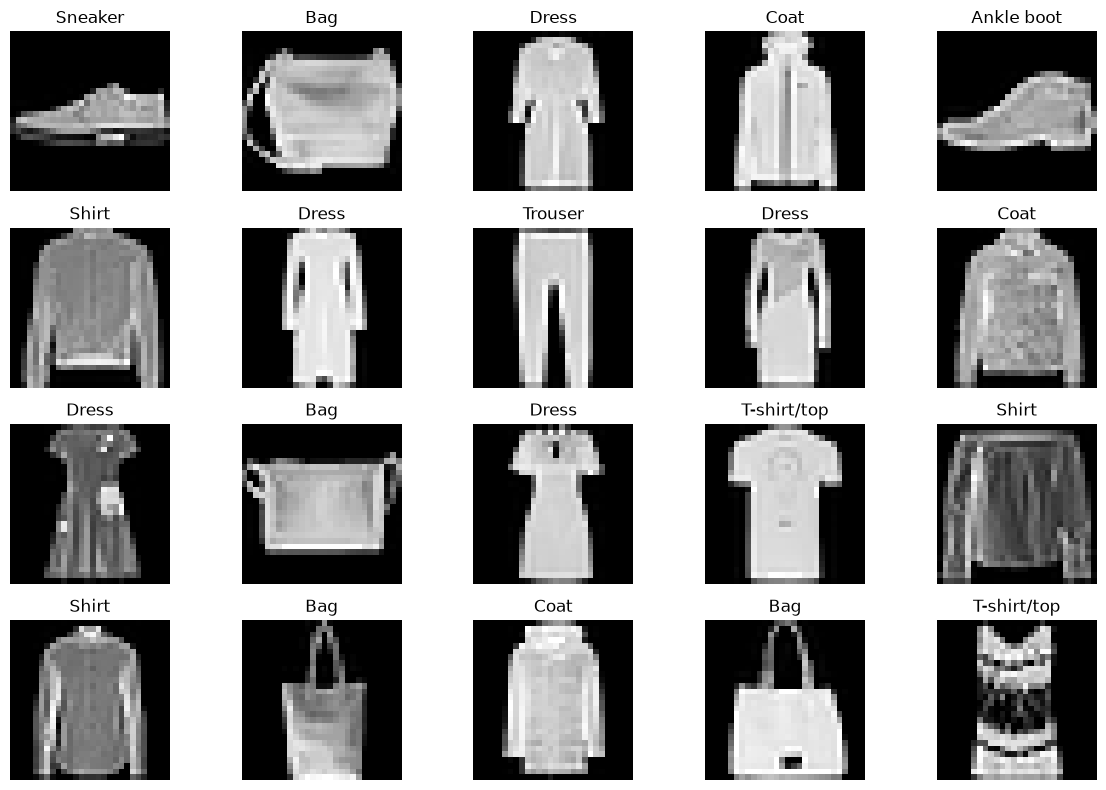

In [14]:
# Visualize processed images
plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# Verify class balance after splitting
def class_distribution(labels):
    counts = ct(labels)
    return [counts[i] for i in range(10)]


final_distribution = pd.DataFrame({
    "Class": class_names,
    "Training": class_distribution(y_train),
    "Validation": class_distribution(y_val),
    "Testing": class_distribution(y_test)
})

final_distribution

,Class,Training,Validation,Testing
0,T-shirt/top,4900,1050,1050
1,Trouser,4900,1050,1050
2,Pullover,4900,1050,1050
3,Dress,4900,1050,1050
4,Coat,4900,1050,1050
5,Sandal,4900,1050,1050
6,Shirt,4900,1050,1050
7,Sneaker,4900,1050,1050
8,Bag,4900,1050,1050
9,Ankle boot,4900,1050,1050


In [16]:
from pathlib import Path
import numpy as np

DATA_DIR = Path("../data/processed")
DATA_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    DATA_DIR / "fashion_mnist_processed.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

print("Processed dataset saved successfully.")
print("File:", (DATA_DIR / "fashion_mnist_processed.npz").resolve())

Processed dataset saved successfully.
File: C:\Desktop\SEM 5\Pattern\EN3150-CNN-Classification\data\processed\fashion_mnist_processed.npz


In [17]:
assert X_train.shape == (49000, 28, 28, 1)
assert X_val.shape == (10500, 28, 28, 1)
assert X_test.shape == (10500, 28, 28, 1)

assert X_train.min() >= 0 and X_train.max() <= 1
assert X_val.min() >= 0 and X_val.max() <= 1
assert X_test.min() >= 0 and X_test.max() <= 1

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("All dataset checks passed.")

All dataset checks passed.


#### **7. Summary**
The Fashion-MNIST dataset was successfully explored and prepared for CNN-based classification.

##### Dataset
- Total images: 70,000
- Image resolution: 28 × 28
- Image type: Grayscale
- Number of classes: 10

##### Dataset Split
- Training: 49,000 images (70%)
- Validation: 10,500 images (15%)
- Testing: 10,500 images (15%)

##### Preprocessing
The following preprocessing operations were performed:
1. Combined the available Fashion-MNIST samples.
2. Created a stratified 70/15/15 train-validation-test split.
3. Converted pixel values from integers to floating-point values.
4. Normalized pixel values from [0, 255] to [0, 1].
5. Added a single channel dimension for CNN input.

The resulting input shape for the CNN models is:
$$
28 \times 28 \times 1
$$

The processed dataset is now ready for the development of the custom CNN architectures.